In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Лабораторная работа №1
- Напишите программу для распознавания растровых изображений, используя метод k ближайшего соседа (kNN). 
- Реализуйте программно равномерное и неравномерное зашумление изображений и сравните процент распознавания для используемых норм в случаях распознавания растровых бинарных изображений и изображений в градациях серого цвета для различных k. 
- В качестве мер близости используйте предложенные выше и сравните результаты их применения.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [3]:
SEED = 42

if "df" not in globals():
    df = fetch_openml("mnist_784")

In [4]:
df.target

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [5]:
X = df.data.to_numpy()
y = df.target.to_numpy().astype(int)

X.shape

(70000, 784)

In [6]:
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

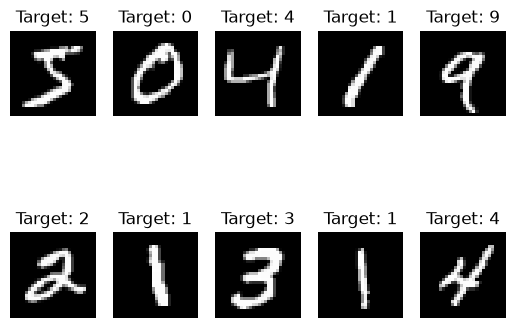

In [7]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Target: {df.target[i]}")
    plt.axis("off")

In [8]:
rng = np.random.default_rng(SEED)
tr = rng.choice(len(X_train), size=10000, replace=False)
te = rng.choice(len(X_test), size=1000, replace=False)

Xtr = (
    X_train[tr]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
) / 255

Xte = (
    X_test[te]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
    / 255
)

ytr, yte = y_train[tr], y_test[te]

Xtr_bin, Xte_bin = (Xtr > 0.5).astype(np.float32), (Xte > 0.5).astype(np.float32)

[(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5)),
 (np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))]

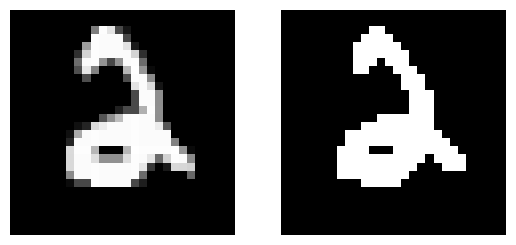

In [9]:
fig, axes = plt.subplots(1, 2)
axes[0].imshow(Xtr[0].reshape(28, 28), cmap="gray")
axes[1].imshow(Xtr_bin[0].reshape(28, 28), cmap="gray")
[ax.axis("off") for ax in axes]

### Функции зашумления: для бинарных и оттенков серого - равномерное и неравномерное

In [10]:
def noise_uni_bin(X, p=0.1):
    """Равномерное зашумление бинарного изображения с вероятностью p"""
    mask = rng.random(X.shape) < p
    return np.where(mask, 1 - X, X)


def make_map(v_max):
    t = np.arange(28) / 27
    m = t[None, :]
    return np.broadcast_to(m, (28, 28)).ravel() * v_max


def noise_nonuni_bin(X, p_max=0.5):
    """Нерaвномерное зашумление бинарного изображения с вероятностью p_max"""
    mask = rng.random(X.shape) < make_map(p_max)
    return np.where(mask, 1 - X, X)


def noise_uni_gray(X, p=0.1):
    """Равномерное зашумление серого (255) изображения с вероятностью p"""
    mask = rng.random(X.shape) < p
    return np.where(mask, rng.random(X.shape), X)


def noise_nonuni_gray(X, p_max=0.5):
    """Нерaвномерное зашумление серого (255) изображения с вероятностью p_max"""
    mask = rng.random(X.shape) < make_map(p_max)
    return np.where(mask, rng.random(X.shape), X)

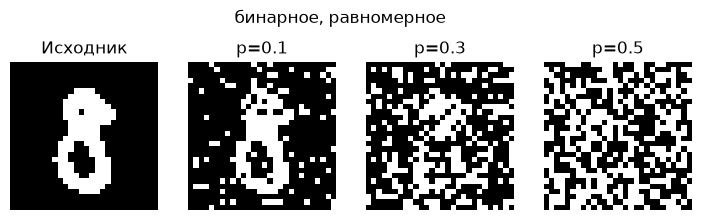

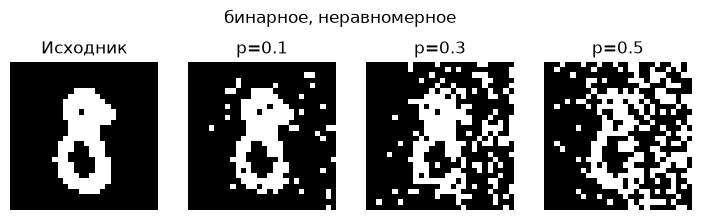

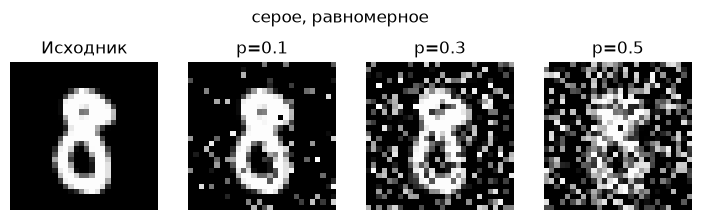

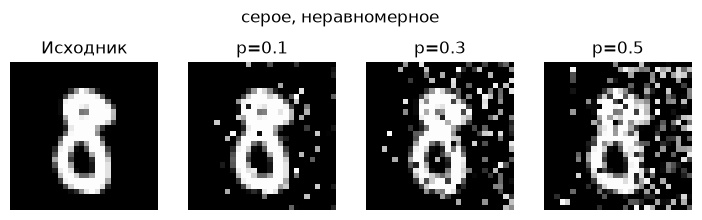

In [11]:
i = 0


def show_noise(x, fn, levels=(0.1, 0.3, 0.5), title=""):
    fig, axes = plt.subplots(1, len(levels) + 1, figsize=(2.2 * (len(levels) + 1), 2.6))
    axes[0].imshow(x.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Исходник")
    for ax, p in zip(axes[1:], levels):
        ax.imshow(fn(x, p).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"p={p}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_noise(Xte_bin[i], noise_uni_bin, title="бинарное, равномерное")
show_noise(Xte_bin[i], noise_nonuni_bin, title="бинарное, неравномерное")
show_noise(Xte[i], noise_uni_gray, title="серое, равномерное")
show_noise(Xte[i], noise_nonuni_gray, title="серое, неравномерное")

### Функции расстояния.
*Меры:*
- Евклидово	```p(a, b) = √Σ(aᵢ − bᵢ)²```
- Квадрат евклидова	```p(a, b) = Σ(aᵢ − bᵢ)²```
- Взвешенное евклидово	```p(a, b) = √Σ wᵢ(aᵢ − bᵢ)²```
- Манхэттенское	```p(a, b) = Σ|aᵢ − bᵢ|```
- Чебышёва	```p(a, b) = max|aᵢ − bᵢ|```

In [12]:
def euclidean(A, B, squared=False):
    a2 = (A**2).sum(axis=1)[:, None]
    b2 = (B**2).sum(axis=1)[None, :]
    d2 = a2 + b2 - 2.0 * (A @ B.T)
    np.maximum(d2, 0, out=d2)
    return d2 if squared else np.sqrt(d2)


def manhattan(A, B, batch=16):
    D = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(0, len(A), batch):
        chunk = A[i : i + batch]
        diff = np.abs(chunk[:, None, :] - B[None, :, :])
        D[i : i + batch] = diff.sum(axis=-1)
    return D


def weighted_euclidean(A, B, w, squared=False):
    s = np.sqrt(w).astype(np.float32)
    return euclidean(s * A, s * B, squared=squared)


def chebyshev(A, B, batch=16):
    D = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(0, len(A), batch):
        chunk = A[i : i + batch]
        diff = np.abs(chunk[:, None, :] - B[None, :, :])
        D[i : i + batch] = diff.max(axis=-1)
    return D

### Реализация kNN

In [ ]:
from collections import Counter, defaultdict


def knn(
    D: np.ndarray, ytr: np.ndarray, yte: np.ndarray, key: list[int]
) -> dict[int, float]:
    idx = np.argsort(D, axis=1)
    counts = defaultdict(int)
    for i in range(len(D)):
        for c in key:
            counter = Counter(ytr[idx[i, 0:c]])
            if max(counter, key=counter.get) == yte[i]:
                counts[c] += 1
    for key, value in counts.items():
        counts[key] = value / len(D) * 100
    return dict(counts)


def knn_fast(D, ytr, yte, ks):
    kmax = max(ks)
    part = np.argpartition(D, kmax, axis=1)[:, :kmax]
    order = np.argsort(np.take_along_axis(D, part, axis=1), axis=1)
    idx = np.take_along_axis(part, order, axis=1)
    votes = ytr[idx]

    res = {}
    for k in ks:
        onehot = np.eye(10, dtype=np.float32)[votes[:, :k]]
        w = 1.0 + 1e-6 * np.arange(k, 0, -1, dtype=np.float32)
        pred = (onehot * w[None, :, None]).sum(axis=1).argmax(axis=1)
        res[k] = float((pred == yte).mean() * 100)
    return res

In [ ]:
from time import time

D = euclidean(Xte, Xtr)

t1 = time()
print(knn(D, ytr, yte, [1, 3, 5, 7]))
print(time() - t1)

t2 = time()
print(knn_fast(D, ytr, yte, [1, 3, 5, 7]))
print(time() - t2)

{1: 95.6, 3: 95.39999999999999, 5: 95.7, 7: 95.39999999999999}
0.19857144355773926
{1: 95.6, 3: 95.39999999999999, 5: 95.7, 7: 95.39999999999999}
0.04053759574890137


### Сравнения бинарных и серых на разных мерах с k=[1, 3, 5, 7]

In [136]:
w_var = Xtr.var(axis=0).astype(np.float32)
w_var_bin = Xtr_bin.var(axis=0).astype(np.float32)
ks = [1, 3, 5, 7]

checks = {
    "серые, евклидово": euclidean(Xte, Xtr),
    "серые, квадрат евклидова": euclidean(Xte, Xtr, squared=True),
    "серые, манхэттен": manhattan(Xte, Xtr),
    "серые, чебышёв": chebyshev(Xte, Xtr),
    "серые, взвешенное": weighted_euclidean(Xte, Xtr, w_var),
    "бинарные, евклидово": euclidean(Xte_bin, Xtr_bin),
    "бинарные, манхэттен": euclidean(Xte_bin, Xtr_bin, squared=True),
    "бинарные, чебышёв": chebyshev(Xte_bin, Xtr_bin),
    "бинарные, взвешенное": weighted_euclidean(Xte_bin, Xtr_bin, w_var_bin),
}

for name, D in checks.items():
    acc = knn_fast(D, ytr, yte, ks)
    print(f"{name:30s} " + "  ".join(f"k={k}: {acc[k]:.1f}" for k in ks))

серые, евклидово               k=1: 95.6  k=3: 95.4  k=5: 95.7  k=7: 95.4
серые, квадрат евклидова       k=1: 95.6  k=3: 95.4  k=5: 95.7  k=7: 95.4
серые, манхэттен               k=1: 94.4  k=3: 94.6  k=5: 95.0  k=7: 94.3
серые, чебышёв                 k=1: 69.2  k=3: 69.4  k=5: 70.7  k=7: 70.5
серые, взвешенное              k=1: 95.4  k=3: 95.2  k=5: 95.3  k=7: 94.9
бинарные, евклидово            k=1: 93.3  k=3: 94.3  k=5: 94.6  k=7: 94.4
бинарные, манхэттен            k=1: 93.3  k=3: 94.3  k=5: 94.6  k=7: 94.4
бинарные, чебышёв              k=1: 10.6  k=3: 10.6  k=5: 10.6  k=7: 7.4
бинарные, взвешенное           k=1: 94.3  k=3: 94.4  k=5: 94.9  k=7: 94.9


In [ ]:
import time
import pandas as pd

K_LIST = [1, 3, 5, 7, 11, 15]
P_LEVELS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
MEASURES = [
    "Евклидово",
    "Квадрат евклидова",
    "Манхэттенское",
    "Чебышёва",
    "Взвешенное евклидово",
]

SETUPS = {
    "бинарные": dict(
        Btr=Xtr_bin,
        Bte=Xte_bin,
        is_bin=True,
        noise={"равномерный": noise_uni_bin, "неравномерный": noise_nonuni_bin},
    ),
    "серые": dict(
        Btr=Xtr,
        Bte=Xte,
        is_bin=False,
        noise={"равномерный": noise_uni_gray, "неравномерный": noise_nonuni_gray},
    ),
}

for cfg in SETUPS.values():
    w = cfg["Btr"].var(axis=0).astype(np.float32)
    cfg["s"] = np.sqrt(w)
    cfg["Btr_w"] = cfg["Btr"] * cfg["s"]


def distance(name, A, cfg):
    Btr = cfg["Btr"]
    if name == "Евклидово":
        return euclidean(A, Btr)
    if name == "Квадрат евклидова":
        return euclidean(A, Btr, squared=True)
    if name == "Манхэттенское":
        return euclidean(A, Btr, squared=True) if cfg["is_bin"] else manhattan(A, Btr)
    if name == "Чебышёва":
        return chebyshev(A, Btr)
    if name == "Взвешенное евклидово":
        return euclidean(A * cfg["s"], cfg["Btr_w"])


rows = []
t0 = time.time()
for img_type, cfg in SETUPS.items():
    for noise_type, noise_fn in cfg["noise"].items():
        for p in P_LEVELS:
            level = p if noise_type == "равномерный" else min(2 * p, 1.0)
            A = cfg["Bte"] if p == 0 else noise_fn(cfg["Bte"], level)

            for m in MEASURES:
                D = distance(m, A, cfg)
                acc = knn_fast(D, ytr, yte, K_LIST)
                del D
                for k, v in acc.items():
                    rows.append(
                        dict(тип=img_type, шум=noise_type, p=p, мера=m, k=k, acc=v)
                    )
            print(
                f"{img_type:10s} {noise_type:14s} p={p:.2f}  "
                f"[{time.time()-t0:5.0f} c]"
            )

df = pd.DataFrame(rows)
df.to_csv("results.csv", index=False)

бинарные   равномерный    p=0.00  [   19 c]
бинарные   равномерный    p=0.05  [   38 c]
бинарные   равномерный    p=0.10  [   57 c]
бинарные   равномерный    p=0.20  [   76 c]
бинарные   равномерный    p=0.30  [   94 c]
бинарные   равномерный    p=0.40  [  114 c]
бинарные   равномерный    p=0.50  [  132 c]
бинарные   неравномерный  p=0.00  [  151 c]
бинарные   неравномерный  p=0.05  [  169 c]
бинарные   неравномерный  p=0.10  [  187 c]
бинарные   неравномерный  p=0.20  [  205 c]
бинарные   неравномерный  p=0.30  [  224 c]
бинарные   неравномерный  p=0.40  [  242 c]
бинарные   неравномерный  p=0.50  [  260 c]
серые      равномерный    p=0.00  [  296 c]
серые      равномерный    p=0.05  [  372 c]
серые      равномерный    p=0.10  [  448 c]
серые      равномерный    p=0.20  [  521 c]
серые      равномерный    p=0.30  [  595 c]
серые      равномерный    p=0.40  [  668 c]
серые      равномерный    p=0.50  [  742 c]
серые      неравномерный  p=0.00  [  778 c]
серые      неравномерный  p=0.05

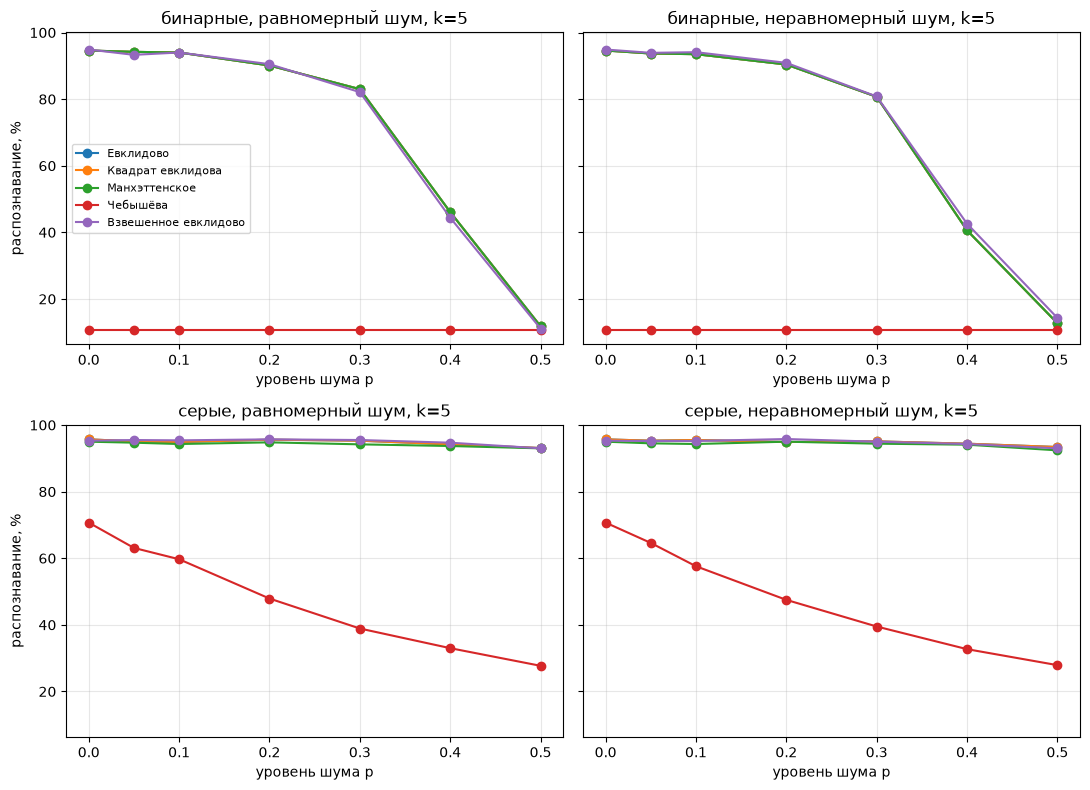

In [147]:
import matplotlib.pyplot as plt


def plot_vs_noise(df, k):
    combos = [(t, n) for t in df["тип"].unique() for n in df["шум"].unique()]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
    for ax, (t, n) in zip(axes.ravel(), combos):
        sub = df[(df["тип"] == t) & (df["шум"] == n) & (df["k"] == k)]
        for m in MEASURES:
            s = sub[sub["мера"] == m].sort_values("p")
            ax.plot(s["p"], s["acc"], marker="o", label=m)
        ax.set_title(f"{t}, {n} шум, k={k}")
        ax.set_xlabel("уровень шума p")
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("распознавание, %")
    axes[1, 0].set_ylabel("распознавание, %")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_vs_noise(df, k=5)

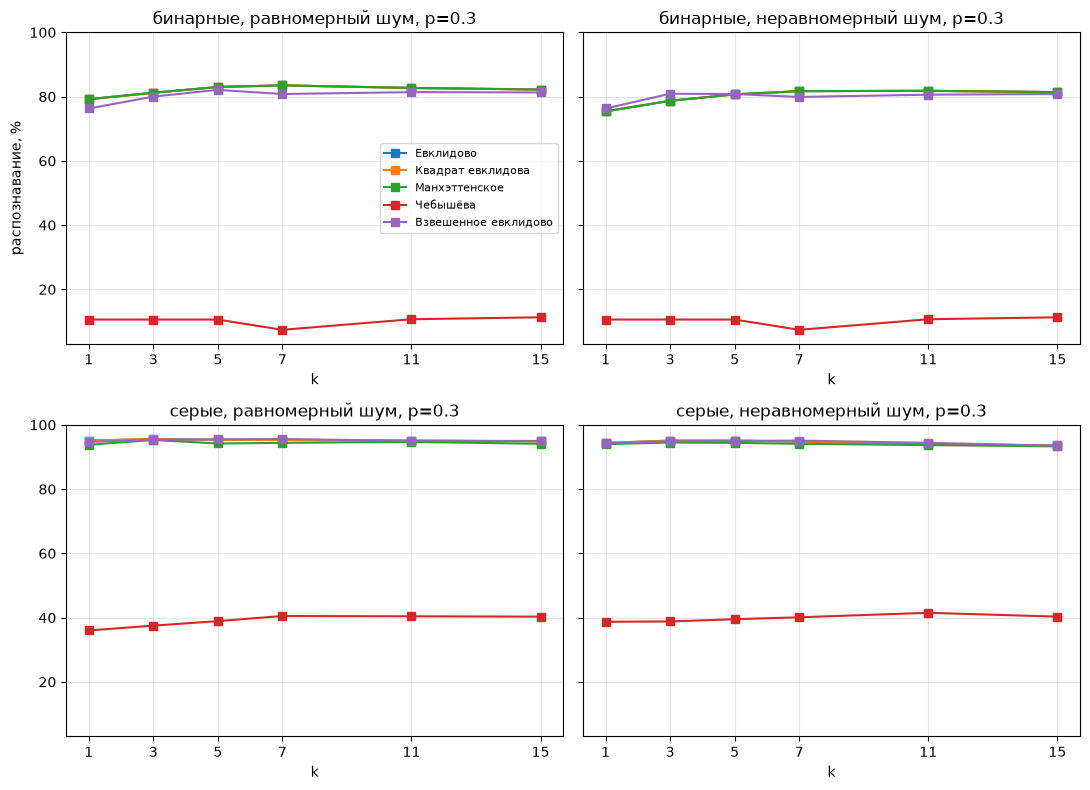

In [148]:
def plot_vs_k(df, p):
    combos = [(t, n) for t in df["тип"].unique() for n in df["шум"].unique()]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
    for ax, (t, n) in zip(axes.ravel(), combos):
        sub = df[(df["тип"] == t) & (df["шум"] == n) & (df["p"] == p)]
        for m in MEASURES:
            s = sub[sub["мера"] == m].sort_values("k")
            ax.plot(s["k"], s["acc"], marker="s", label=m)
        ax.set_title(f"{t}, {n} шум, p={p}")
        ax.set_xlabel("k")
        ax.set_xticks(K_LIST)
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("распознавание, %")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_vs_k(df, p=0.3)

In [149]:
print(
    df[df.k == 5]
    .pivot_table(index=["тип", "шум", "p"], columns="мера", values="acc")
    .round(1)
)

мера                         Взвешенное евклидово  Евклидово  \
тип      шум           p                                       
бинарные неравномерный 0.00                  94.9       94.6   
                       0.05                  93.9       93.7   
                       0.10                  94.1       93.5   
                       0.20                  90.9       90.4   
                       0.30                  80.8       80.7   
                       0.40                  42.6       40.6   
                       0.50                  14.3       12.7   
         равномерный   0.00                  94.9       94.6   
                       0.05                  93.3       94.2   
                       0.10                  94.0       94.0   
                       0.20                  90.5       90.1   
                       0.30                  82.1       83.0   
                       0.40                  44.4       46.1   
                       0.50             